# Panel Belanja: Household × Minggu, dan Timeline Campaign

Seluruh analisis voucher di proyek ini berdiri di atas satu tabel sederhana: apa yang terjadi pada tiap household di tiap minggu. Notebook ini membangun tabel itu — panel `hh_week` (2.500 household × 102 minggu) — beserta timeline 30 campaign, langsung dari transaksi mentah.

Definisi yang dipakai di sini mengikat semua analisis berikutnya: spend = **net** (`SALES_VALUE` + seluruh diskon; diskon tersimpan sebagai nilai negatif), baris retur tetap masuk agregasi tanpa di-drop, intensitas promo diukur dengan `promo_share`, dan "baru belanja kapan" diukur dalam minggu. Versi formalnya tercatat di `docs/decision-log.md`.

Dua hal yang dicari di fondasi ini: apakah data cukup bersih untuk dipanelkan, dan campaign mana yang masih menyisakan control group yang layak untuk analisis efek voucher.

> Semua di sini deskriptif — tidak ada model, tidak ada klaim kausal. Angka-angka kunci dikunci sebagai test di `tests/test_panel.py`, jadi kalau data berganti, kerusakannya langsung terlihat.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Repo-root import shim: works both from notebooks/ and from repo root
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.features import (
    N_WEEKS,
    PROCESSED_DIR,
    build_campaign_timeline,
    build_day_week_bridge,
    build_hh_campaign,
    build_hh_category,
    build_hh_week,
    classify_campaign_eligibility,
    compute_control_pool,
    load_campaign_desc,
    load_campaign_treated,
    product_join_coverage,
    read_day_week_pairs,
    read_households,
    save_parquet,
    spend_sanity,
)

print("pandas", pd.__version__, "| duckdb", duckdb.__version__)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 40)

pandas 3.0.3 | duckdb 2.0.0


## 1. Jembatan hari → minggu

Minggu retailer di data ini tidak selalu 7 hari — minggu pertama hanya 5 hari, dan batas-batas selanjutnya tidak beraturan. Karena itu pemetaan hari → minggu harus dibangun dari kolom `WEEK_NO` yang benar-benar terobservasi, bukan dihitung dengan `floor((DAY-1)/7)+1`: rumus itu meleset untuk ±27% baris dan diam-diam menggeser semua window campaign.

 week_no  min_day  max_day  n_days
       1        1        5       5
       2        6       12       7
       3       13       19       7
minggu: 102 | hari: 1-711 | minggu dengan panjang != 7 hari: 2


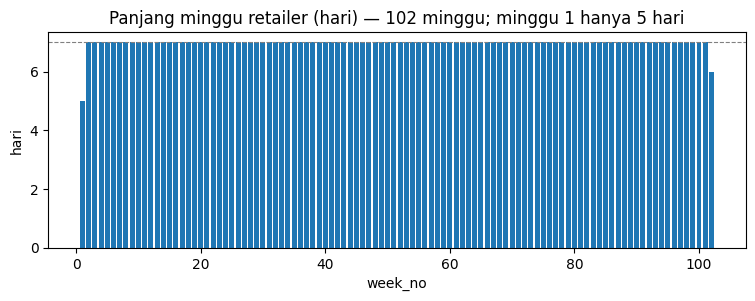

In [2]:
bridge = build_day_week_bridge(read_day_week_pairs())
bridge = bridge.assign(n_days=bridge["max_day"] - bridge["min_day"] + 1)
print(bridge.head(3).to_string(index=False))
print(
    f"minggu: {len(bridge)} | hari: {bridge['min_day'].min()}-{bridge['max_day'].max()} | "
    f"minggu dengan panjang != 7 hari: {(bridge['n_days'] != 7).sum()}"
)

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.bar(bridge["week_no"], bridge["n_days"], color="#1f77b4")
ax.axhline(7, color="gray", lw=0.8, ls="--")
ax.set(
    title="Panjang minggu retailer (hari) — 102 minggu; minggu 1 hanya 5 hari",
    xlabel="week_no",
    ylabel="hari",
)
plt.show()

## 2. Timeline 30 campaign

Setiap campaign punya window `[start_day, end_day]` yang bisa beririsan dengan campaign lain — 74 pasang campaign saling bertumpuk. Timeline di bawah memetakan window itu ke minggu (lewat jembatan, tentunya), menghitung berapa household yang ditarget, dan menandai campaign yang window-nya terpotong akhir data.

Satu hal yang menohok: campaign 26 mulai hari 224, yang menurut `WEEK_NO` aktual jatuh di **minggu 33** — bukan minggu 32 seperti hasil rumus naive. Dua hari yang "hilang" di minggu pertama menggeser semuanya.

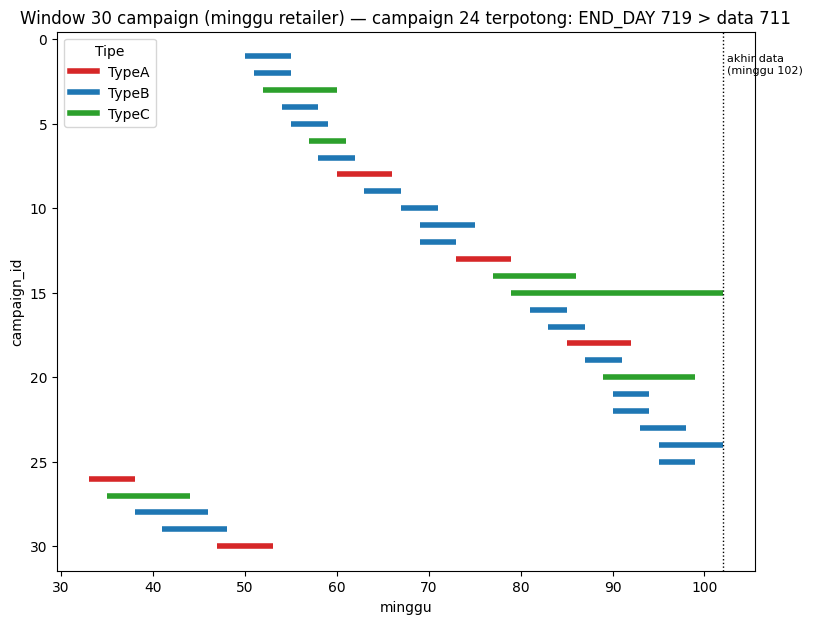

,campaign_id,type,start_day,end_day,start_week,end_week,n_treated,n_overlaps,truncated_flag
0,1,B,346,383,50,55,13,5,False
1,2,B,351,383,51,55,48,5,False
2,3,C,356,412,52,60,12,8,False
3,4,B,372,404,54,58,81,6,False
4,5,B,377,411,55,59,166,6,False
5,6,C,393,425,57,61,65,5,False
6,7,B,398,432,58,62,198,5,False
7,8,A,412,460,60,66,1076,4,False
8,9,B,435,467,63,67,176,2,False
9,10,B,463,495,67,71,123,3,False


In [3]:
timeline = build_campaign_timeline(load_campaign_desc(), load_campaign_treated(), bridge)

type_colors = {"A": "#d62728", "B": "#1f77b4", "C": "#2ca02c"}
fig, ax = plt.subplots(figsize=(9, 7))
for r in timeline.itertuples():
    ax.hlines(r.campaign_id, r.start_week, r.end_week, color=type_colors[r.type], lw=4)
ax.axvline(N_WEEKS, color="black", ls=":", lw=1)
ax.text(N_WEEKS + 0.5, 2, "akhir data\n(minggu 102)", fontsize=8)
ax.set(
    title="Window 30 campaign (minggu retailer) — campaign 24 terpotong: END_DAY 719 > data 711",
    xlabel="minggu",
    ylabel="campaign_id",
)
ax.legend(
    [plt.Line2D([], [], color=c, lw=4) for c in type_colors.values()],
    [f"Type{t}" for t in type_colors],
    title="Tipe",
)
ax.invert_yaxis()
plt.show()

timeline[
    ["campaign_id", "type", "start_day", "end_day", "start_week", "end_week",
     "n_treated", "n_overlaps", "truncated_flag"]
]

## 3. Berapa yang benar-benar dibayar? Definisi spend dan retur

`SALES_VALUE` bukan uang yang dibayar: diskon kartu loyalty, kupon manufacturer, dan matching kupon retailer tersimpan sebagai nilai negatif di kolom terpisah. Spend di proyek ini karenanya memakai definisi net — `SALES_VALUE + RETAIL_DISC + COUPON_DISC + COUPON_MATCH_DISC` — dipakai konsisten di semua analisis.

Baris retur/penyesuaian (net negatif, atau `SALES_VALUE ≤ 0`) **tidak dibuang**: nilainya masuk agregasi apa adanya, dan minggu yang memuatnya ditandai `has_return`. Membuang ±3% baris akan menggeser level spend tanpa ada yang menyadarinya.

In [4]:
s = spend_sanity()
expected = {"n_rows": 2_595_732, "n_sales_value_le0": 18_850, "n_net_lt0": 80_890}
sanity_table = pd.DataFrame(
    [(k, f"{v:,.2f}" if isinstance(v, float) else f"{v:,}",
      (f"{expected[k]:,}" if k in expected else "—")) for k, v in s.items()],
    columns=["statistik", "nilai (dihitung)", "target terverifikasi (AGENTS.md §3.2)"],
)
share_excluded = 1 - s["n_denominator_valid"] / s["n_rows"]
display(sanity_table)
print(f"Share baris penyebut tidak valid (dikecualikan dari promo_share, DL-004): {share_excluded:.4%}")
print("Kebijakan retur (DL-002): 18.850 baris SALES_VALUE<=0 dan 80.890 baris net<0 TIDAK di-drop — masuk agregasi, hanya di-flag `has_return`.")

,statistik,nilai (dihitung),target terverifikasi (AGENTS.md §3.2)
0,n_rows,"2,595,732","2,595,732"
1,n_sales_value_le0,"18,850","18,850"
2,n_net_lt0,"80,890","80,890"
3,n_denominator_valid,"2,576,882",—
4,net_sum,"6,608,940.89",—
5,net_min,-100.02,—
6,net_p50,1.69,—
7,net_p99,19.50,—
8,net_max,840.00,—


Share baris penyebut tidak valid (dikecualikan dari promo_share, DL-004): 0.7262%
Kebijakan retur (DL-002): 18.850 baris SALES_VALUE<=0 dan 80.890 baris net<0 TIDAK di-drop — masuk agregasi, hanya di-flag `has_return`.


## 4. Panel `hh_week`: 2.500 household × 102 minggu

Panel dibuat *balanced* — setiap household punya baris di setiap minggu, termasuk minggu tanpa transaksi. Minggu kosong bukan data hilang: deretannya adalah informasi tenure dan recency, dan justru bahan utama untuk membaca perilaku di analisis berikutnya.

In [5]:
panel = build_hh_week()
save_parquet(panel, PROCESSED_DIR / "hh_week.parquet")
assert not panel.duplicated(["household_key", "week_no"]).any()
assert len(panel) == 2_500 * N_WEEKS
print(f"panel: {panel.shape[0]:,} baris × {panel.shape[1]} kolom — unik OK")
panel.head()

panel: 255,000 baris × 16 kolom — unik OK


,household_key,week_no,net_spend,n_baskets,n_products,category_breadth,has_purchase,has_return,n_suspect_rows,promo_share,promo_numerator,promo_denominator,sales_value_sum,abs_retail_disc_sum,abs_coupon_disc_sum,recency_weeks
0,1,1,0.0,0,0,0,False,False,0,NaN,0.0,0.0,0.0,0.0,0.0,<NA>
1,1,2,0.0,0,0,0,False,False,0,NaN,0.0,0.0,0.0,0.0,0.0,<NA>
2,1,3,0.0,0,0,0,False,False,0,NaN,0.0,0.0,0.0,0.0,0.0,<NA>
3,1,4,0.0,0,0,0,False,False,0,NaN,0.0,0.0,0.0,0.0,0.0,<NA>
4,1,5,0.0,0,0,0,False,False,0,NaN,0.0,0.0,0.0,0.0,0.0,<NA>


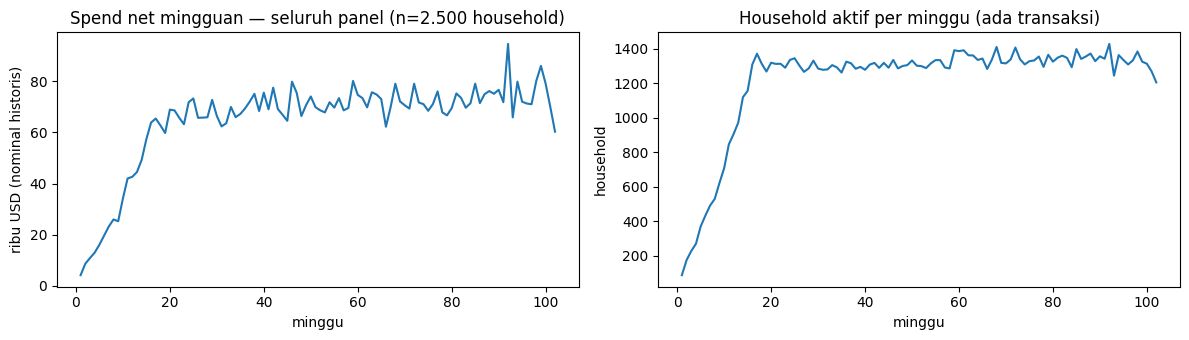

In [6]:
weekly = panel.groupby("week_no").agg(
    net_spend=("net_spend", "sum"), n_active=("has_purchase", "sum")
)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(weekly.index, weekly["net_spend"] / 1e3)
axes[0].set(
    title="Spend net mingguan — seluruh panel (n=2.500 household)",
    xlabel="minggu", ylabel="ribu USD (nominal historis)",
)
axes[1].plot(weekly.index, weekly["n_active"])
axes[1].set(
    title="Household aktif per minggu (ada transaksi)",
    xlabel="minggu", ylabel="household",
)
plt.tight_layout()
plt.show()

## 5. Seberapa bergantung pada promo? `promo_share`

Rasio nilai diskon terhadap nilai jual per minggu: `Σ(|RETAIL_DISC| + |COUPON_DISC|) / Σ(SALES_VALUE)`, hanya pada baris `SALES_VALUE > 0` — minggu tanpa baris demikian menjadi NA, bukan nol.

Ekor di atas 1 memang ada (minggu saat nilai diskon melampaui sales: transaksi bernilai sangat kecil dengan diskon besar). Dilaporkan apa adanya, tidak dipangkas.

p50=0.1515 | p90=0.3658 | p99=0.7795 | max=8.248
minggu NA (tanpa baris penyebut valid): 131,112 (51.4% dari 255.000) | minggu promo_share > 1: 347 (0.280% dari minggu valid)


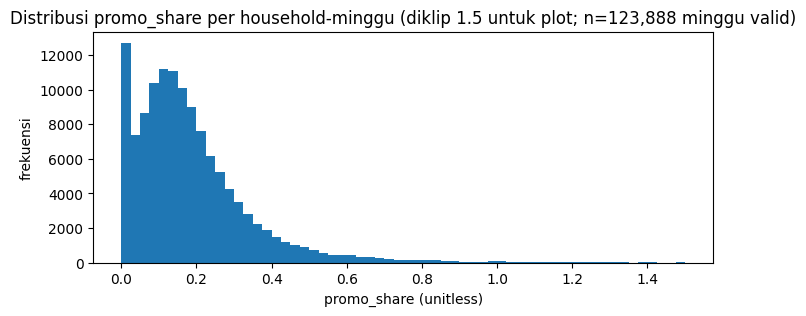

In [7]:
ps = panel["promo_share"]
n_valid = int(ps.notna().sum())
n_gt1 = int((ps > 1).sum())
print(
    f"p50={ps.quantile(.5):.4f} | p90={ps.quantile(.9):.4f} | "
    f"p99={ps.quantile(.99):.4f} | max={ps.max():.3f}"
)
print(
    f"minggu NA (tanpa baris penyebut valid): {int(ps.isna().sum()):,} "
    f"({ps.isna().mean():.1%} dari 255.000) | minggu promo_share > 1: {n_gt1:,} "
    f"({n_gt1 / n_valid:.3%} dari minggu valid)"
)
fig, ax = plt.subplots(figsize=(8, 3))
ps.clip(upper=1.5).plot.hist(bins=60, ax=ax, color="#1f77b4")
ax.set(
    title=f"Distribusi promo_share per household-minggu (diklip 1.5 untuk plot; n={n_valid:,} minggu valid)",
    xlabel="promo_share (unitless)",
    ylabel="frekuensi",
)
plt.show()

## 6. Recency dan tenure

`recency_weeks` = berapa minggu sejak minggu aktif terakhir; 0 di minggu aktif, dan NA sebelum transaksi pertama — member yang belum pernah belanja memang belum bisa disebut "dingin". Distribusi minggu belanja pertama adalah fitur tenure gratis: sebagian household memang terlambat masuk panel.

minggu belanja pertama: median=11 | p90=16 | household sudah aktif di minggu 1: 88
recency non-NA: p50=0 | p90=8 | max=94 | NA=22,788 minggu (pra-transaksi pertama)


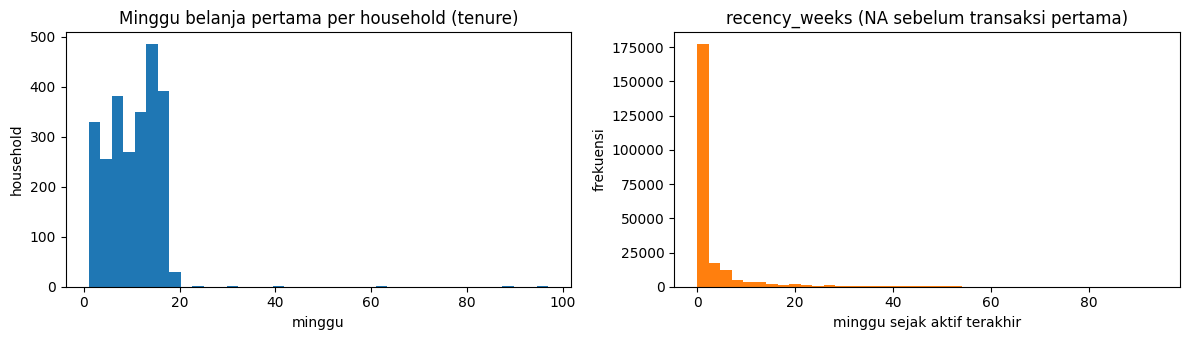

In [8]:
first_week = panel[panel["has_purchase"]].groupby("household_key")["week_no"].min()
rec = panel["recency_weeks"]
print(
    f"minggu belanja pertama: median={first_week.median():.0f} | "
    f"p90={first_week.quantile(.9):.0f} | household sudah aktif di minggu 1: {(first_week == 1).sum():,}"
)
print(
    f"recency non-NA: p50={rec.quantile(.5):.0f} | p90={rec.quantile(.9):.0f} | "
    f"max={rec.max()} | NA={int(rec.isna().sum()):,} minggu (pra-transaksi pertama)"
)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(first_week, bins=40, color="#1f77b4")
axes[0].set(title="Minggu belanja pertama per household (tenure)", xlabel="minggu", ylabel="household")
axes[1].hist(rec.dropna().astype(int), bins=40, color="#ff7f0e")
axes[1].set(title="recency_weeks (NA sebelum transaksi pertama)", xlabel="minggu sejak aktif terakhir", ylabel="frekuensi")
plt.tight_layout()
plt.show()

## 7. Kategori: coverage join & tabel household × komoditas

`category_breadth` (berapa jenis komoditas per minggu) mengharuskan join ke master produk — dan coverage di bawah 100% akan membuat breadth undercount tanpa bersuara, maka dihitung dan dilaporkan. Tabel long household × komoditas yang dihasilkan di sini menjadi bahan analisis penetrasi kategori dan segmentasi.

In [9]:
cov = product_join_coverage()
display(pd.DataFrame(
    [(k, f"{v:.4%}" if isinstance(v, float) else f"{v:,}") for k, v in cov.items()],
    columns=["metrik", "nilai"],
))
hh_cat = build_hh_category()
save_parquet(hh_cat, PROCESSED_DIR / "hh_category.parquet")
print(f"hh_category: {len(hh_cat):,} baris (household × commodity) | {hh_cat['commodity_desc'].nunique()} commodity")
top = hh_cat.groupby("commodity_desc")["net_spend"].sum().sort_values(ascending=False).head(10)
top.to_frame("net_spend total (USD, seluruh panel, 102 minggu)")

,metrik,nilai
0,n_txn_rows,"2,595,732"
1,n_unmatched_rows,0
2,n_distinct_products,"92,339"
3,n_unmatched_products,0
4,row_coverage,100.0000%
5,id_coverage,100.0000%


hh_category: 288,690 baris (household × commodity) | 308 commodity


,"net_spend total (USD, seluruh panel, 102 minggu)"
commodity_desc,
COUPON/MISC ITEMS,619616.71
BEEF,247329.37
SOFT DRINKS,216121.95
FLUID MILK PRODUCTS,157924.24
BEERS/ALES,147232.08
CHEESE,138433.86
BAG SNACKS,126085.78
FROZEN PIZZA,113478.15
FRZN MEAT/MEAT DINNERS,112761.36


## 8. Siapa ditarget campaign apa

Peta treatment: pasangan (household, campaign) beserta window-nya. Perancangan control group, matching, dan pembobotan adalah pekerjaan tersendiri — di sini hanya fakta treatment yang disimpan.

In [10]:
hh_campaign = build_hh_campaign(load_campaign_treated(), timeline)
save_parquet(hh_campaign, PROCESSED_DIR / "hh_campaign.parquet")
print(f"hh_campaign: {len(hh_campaign):,} baris | unik (household, campaign): {not hh_campaign.duplicated(['household_key', 'campaign_id']).any()}")
hh_campaign.head()

hh_campaign: 7,208 baris | unik (household, campaign): True


,household_key,campaign_id,type,start_day,end_day,start_week,end_week,truncated_flag,n_weeks_window
0,1,8,A,412,460,60,66,False,7
1,1,12,B,477,509,69,73,False,5
2,1,13,A,504,551,73,79,False,7
3,1,18,A,587,642,85,92,False,8
4,1,20,C,615,685,89,99,False,11


## 9. Control pool per campaign & kelayakan analisis efek

Control yang benar untuk sebuah campaign bukan sekadar "semua yang tidak ditarget campaign itu": household yang sedang menerima campaign lain dengan window beririsan ikut tercemar. Pool di bawah sudah mengecualikan keduanya.

Campaign yang tidak layak berdiri sendiri ditandai apa adanya — treated terlalu sedikit, window terpotong, atau window identik dengan campaign lain — bukan dibuang diam-diam. Daftar inilah yang menentukan campaign mana yang layak dianalisis pada tahap estimasi efek.

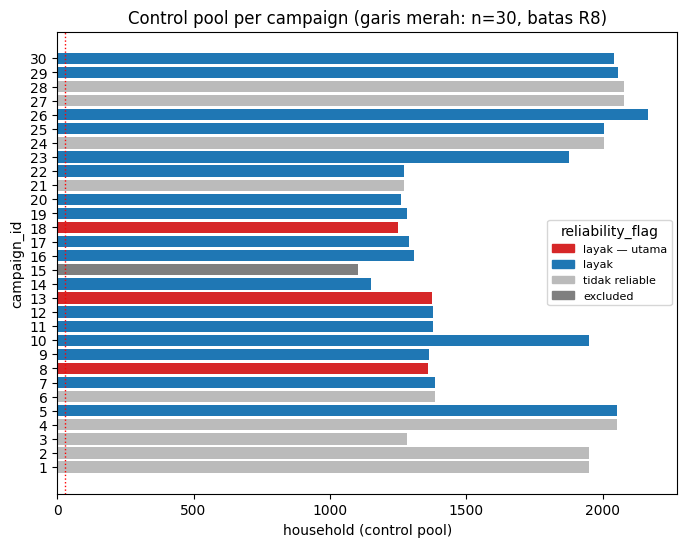

,campaign_id,type,start_week,end_week,n_treated,n_control_pool,n_overlaps,reliability_flag,eligibility_reason
0,1,B,50,55,13,1950,5,tidak reliable,n_treated=13 < 100 — laporkan sebagai agregat
1,2,B,51,55,48,1950,5,tidak reliable,n_treated=48 < 100 — laporkan sebagai agregat
2,3,C,52,60,12,1284,8,tidak reliable,n_treated=12 < 100 — laporkan sebagai agregat
3,4,B,54,58,81,2052,6,tidak reliable,n_treated=81 < 100 — laporkan sebagai agregat
4,5,B,55,59,166,2052,6,layak,"menengah, n_treated=166 — CI akan lebar"
5,6,C,57,61,65,1384,5,tidak reliable,n_treated=65 < 100 — laporkan sebagai agregat
6,7,B,58,62,198,1384,5,layak,"menengah, n_treated=198 — CI akan lebar"
7,8,A,60,66,1076,1359,4,layak — utama,"backbone TypeA, n_treated=1076"
8,9,B,63,67,176,1365,2,layak,"menengah, n_treated=176 — CI akan lebar"
9,10,B,67,71,123,1951,3,layak,"menengah, n_treated=123 — CI akan lebar"


In [11]:
households = read_households()
final_timeline = classify_campaign_eligibility(
    compute_control_pool(load_campaign_treated(), timeline, households)
)
save_parquet(final_timeline, PROCESSED_DIR / "campaign_timeline.parquet")

flag_colors = {"layak — utama": "#d62728", "layak": "#1f77b4",
               "tidak reliable": "#bbbbbb", "excluded": "#7f7f7f"}
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(final_timeline["campaign_id"].astype(str), final_timeline["n_control_pool"],
        color=[flag_colors[f] for f in final_timeline["reliability_flag"]])
ax.axvline(30, color="red", ls=":", lw=1)
ax.set(title="Control pool per campaign (garis merah: n=30, batas R8)",
       xlabel="household (control pool)", ylabel="campaign_id")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in flag_colors.values()],
          list(flag_colors), title="reliability_flag", fontsize=8)
plt.show()

final_timeline[
    ["campaign_id", "type", "start_week", "end_week", "n_treated",
     "n_control_pool", "n_overlaps", "reliability_flag", "eligibility_reason"]
]

## 10. Artefak & angka kunci

In [12]:
artifacts = ["hh_week.parquet", "hh_category.parquet", "hh_campaign.parquet", "campaign_timeline.parquet"]
display(pd.DataFrame(
    [(a, f"{(PROCESSED_DIR / a).stat().st_size / 1e6:.1f} MB") for a in artifacts],
    columns=["artefak (data/processed/)", "ukuran"],
))
print(f"panel: {len(panel):,} baris | promo_share p99: {panel['promo_share'].quantile(.99):.3f} | "
      f"coverage join product: {cov['row_coverage']:.2%}")
print("kelayakan DiD:")
print(final_timeline["reliability_flag"].value_counts().to_string())
bb = final_timeline.set_index("campaign_id").loc[[8, 13, 18], "n_control_pool"].to_dict()
print(f"backbone control pool — campaign 8: {bb[8]:,} | 13: {bb[13]:,} | 18: {bb[18]:,}")

,artefak (data/processed/),ukuran
0,hh_week.parquet,4.5 MB
1,hh_category.parquet,1.3 MB
2,hh_campaign.parquet,0.0 MB
3,campaign_timeline.parquet,0.0 MB


panel: 255,000 baris | promo_share p99: 0.780 | coverage join product: 100.00%
kelayakan DiD:
reliability_flag
layak             17
tidak reliable     9
layak — utama      3
excluded           1
backbone control pool — campaign 8: 1,359 | 13: 1,374 | 18: 1,251


## Catatan kualitas data

- Hari 224 = minggu 33 menurut `WEEK_NO` aktual (bukan 32 hasil rumus naive) — koreksi kecil yang berdampak ke semua window campaign.
- 18.850 baris `SALES_VALUE ≤ 0` dan 80.890 baris net negatif tetap masuk agregasi; 43.478 household-minggu membawa flag `has_return`.
- `promo_share` p99 = 0,78; ekor di atas 1 ada dan tidak dipangkas; 131.112 minggu NA (mayoritas minggu tanpa transaksi).
- Coverage join master produk 100% — `category_breadth` tidak undercount.
- Control pool terkecil untuk campaign yang layak: 1.150 household; backbone 8/13/18: 1.359/1.374/1.251.
- Semua nominal USD historis; tidak ada klaim kausal di notebook ini.